# 7주차 정책 비교: 기준선에서 하나씩 붙이기

`week7_step_by_step.ipynb`와 **같은 설정과 같은 판정 기준**으로, 정책을 하나씩 붙여 가며 비교합니다. 실행과 판정은 `kvbench.experiment.run_week7`을 그대로 호출하고 정책 목록에 LRU Offload만 더합니다.

- 기준선: Pin-All (대기 중에도 유지)
- 단계 1: Evict/Recompute (반대 극단: 대기 시작 즉시 삭제)
- 단계 2: Fixed TTL 3초 (둘 사이: 3초 뒤 삭제)
- 단계 3: LRU Offload (지우지 않고 CPU로 옮김) ← 7주차 매트릭스에 새로 추가

각 단계는 "판정 결과 → 그림 → 동작 검증 → 얻은 것 / 남은 문제 → 다음 단계" 순서입니다. 실제 LLM이나 GPU는 실행하지 않으며, prefill·decode·PCIe 속도는 자리표시자이므로 절대값보다 정책 간 상대 변화를 봅니다.

## 1. 실행 환경과 모듈 불러오기

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from kvbench.experiment import WEEK7_CONDITIONS, WEEK7_POLICIES, WEEK7_SEEDS, run_week7
from kvbench.system import load_policy_params
from kvbench.workload import generate, load_config

pd.set_option('display.precision', 2)
print('python:', sys.version.split()[0])

python: 3.12.7


## 2. 판정 기준 (7주차 공통)

`week7_step_by_step.ipynb` 12절과 같은 기준입니다. seed마다 세 기준을 판정하고, 세 기준을 모두 통과한 seed의 비율을 SLO 통과율로 봅니다.

| Primary 지표 | 기준 |
|---|---|
| 일반 요청 P95 TTFT | 같은 정책 · 같은 seed의 W0 대비 3배 이하 |
| 일반 요청 거절률 | 10% 이하 |
| 최고 KV 점유율 | 90% 이하 |

보조 지표는 원인 설명에만 씁니다: 삭제 횟수 · 재계산 토큰 (LRU Offload는 오프로드 횟수를 함께 봅니다).

## 3. 실험 설정과 60회 실행

7주차 매트릭스(W0 1배 · W1 2배 · W1 4배 × seed 5개)에 정책만 하나 더합니다. 결과 폴더가 이미 있으면 다시 실행하지 않고 재사용합니다.

In [2]:
POLICIES = WEEK7_POLICIES + ('lru_offload',)
LABEL = {'pin_all': 'Pin-All', 'evict_recompute': 'Evict/Recompute',
         'fixed_ttl': 'Fixed TTL 3s', 'lru_offload': 'LRU Offload'}
LOADS = [load for load, _, _ in WEEK7_CONDITIONS]
workload = load_config('configs/week7.json')

OUT = Path('results/week7_policies')
if (OUT / 'comparison.csv').exists():
    print('reuse completed experiment:', OUT.as_posix())
else:
    run_week7('configs/week7.json', 'configs/system_1080ti_llama3b.json', 'configs/policies_week7.json',
              OUT, policies=POLICIES)
raw = pd.read_csv(OUT / 'summary.csv')
comparison = pd.read_csv(OUT / 'comparison.csv')
print(len(raw), 'runs,', len(comparison), 'policy x load rows')

60 runs, 12 policy x load rows


판정표를 정책별로 꺼내는 함수와, run별 점유율 곡선 · 이벤트를 읽는 함수입니다.

In [3]:
def judge(policy):
    part = comparison[comparison.policy == policy].set_index('load').loc[LOADS]
    return pd.DataFrame({
        'P95 TTFT (s)': part.normal_p95_ttft_ms_mean / 1000,
        'TTFT / W0': part.ttft_ratio_vs_policy_1x_mean,
        '거절률 (%)': part.normal_reject_rate_pct_mean,
        '최고 점유율 (%)': part.peak_kv_occupancy_pct_mean,
        'SLO 통과 (%)': part.all_slo_pass_rate_pct,
        '삭제': part.eviction_count_mean,
        '재계산 토큰': part.recomputed_tokens_mean,
    })

def run_dir(policy, wl, lv, seed):
    return OUT / 'runs' / f'{wl.lower()}_s{lv}_seed{seed}__{policy}'

def occupancy(ax, policy, wl, lv, seed, title):
    o = pd.read_csv(run_dir(policy, wl, lv, seed) / 'occupancy.csv')
    ax.step(o.time_ms / 1000, o.used_blocks / o.total_blocks * 100, where='post', lw=1)
    ax.axvspan(0, workload.warmup_ms / 1000, color='0.9')
    ax.axhline(90, color='gray', ls=':')
    ax.set(ylim=(0, 105), ylabel='KV pool used (%)', title=title)

def events(policy, wl, lv, seed):
    return pd.read_csv(run_dir(policy, wl, lv, seed) / 'events.csv')

## 4. 기준선: Pin-All

도구 대기 중에도 KV Cache를 GPU에 그대로 둡니다(vLLM 기본 동작). 이후 모든 단계는 이 표와 비교합니다.

In [4]:
base = judge('pin_all')
display(base)

,P95 TTFT (s),TTFT / W0,거절률 (%),최고 점유율 (%),SLO 통과 (%),삭제,재계산 토큰
load,,,,,,,
1x,0.26,1.00,0.00,66.29,100.0,0.0,0.0
2x,0.26,1.01,0.00,85.25,60.0,0.0,0.0
4x,14.23,61.33,1.99,98.41,0.0,0.0,0.0


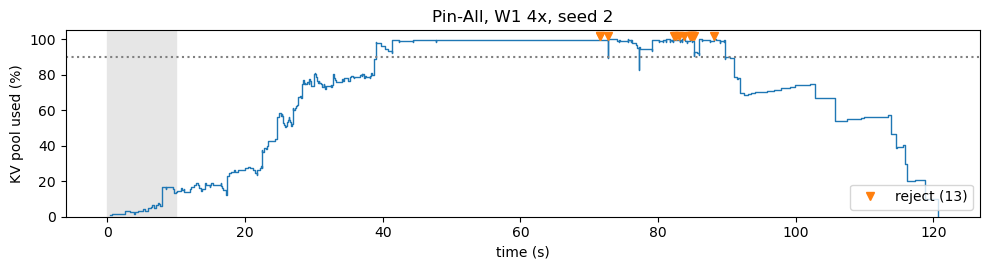

In [5]:
fig, ax = plt.subplots(figsize=(10, 2.8))
occupancy(ax, 'pin_all', 'W1', 4, 2, 'Pin-All, W1 4x, seed 2')
r = events('pin_all', 'W1', 4, 2).query("event == 'REJECT'").time_ms / 1000
ax.plot(r, [102] * len(r), 'v', label=f'reject ({len(r)})')
ax.set_xlabel('time (s)'); ax.legend(loc='lower right')
plt.tight_layout()

**읽는 법**: 1배는 통과하지만, 2배에서는 점유율이 90%를 넘는 seed가 생기고(통과 60%), 4배에서는 TTFT가 W0의 61배 · 점유율 98%로 모든 seed가 떨어집니다. 도구를 기다리는 세션이 블록을 쥔 채 놓지 않아 새 요청이 입장 대기를 하기 때문입니다(곡선이 100%에 붙은 구간).

**남은 문제 → 단계 1**: 기다리는 동안 쥐고 있는 메모리를 비우면 어떻게 되나.

## 5. 단계 1: Evict/Recompute

반대 극단입니다. 도구 대기가 시작되는 순간 지우고, 복귀하면 이전 문맥 전체를 다시 prefill합니다.

In [6]:
step1 = judge('evict_recompute')
display(pd.concat({'Evict/Recompute': step1, 'Pin-All (기준선)': base}, axis=1).T)

load                                 1x         2x         4x
Evict/Recompute P95 TTFT (s)       0.63       0.49       0.47
                TTFT / W0          1.00       0.81       0.77
                거절률 (%)            0.00       0.00       0.00
                최고 점유율 (%)        63.58      61.37      54.61
                SLO 통과 (%)       100.00     100.00     100.00
                삭제                36.20      36.20      36.20
                재계산 토큰        126002.80  126002.80  126002.80
Pin-All (기준선)   P95 TTFT (s)       0.26       0.26      14.23
                TTFT / W0          1.00       1.01      61.33
                거절률 (%)            0.00       0.00       1.99
                최고 점유율 (%)        66.29      85.25      98.41
                SLO 통과 (%)       100.00      60.00       0.00
                삭제                 0.00       0.00       0.00
                재계산 토큰             0.00       0.00       0.00

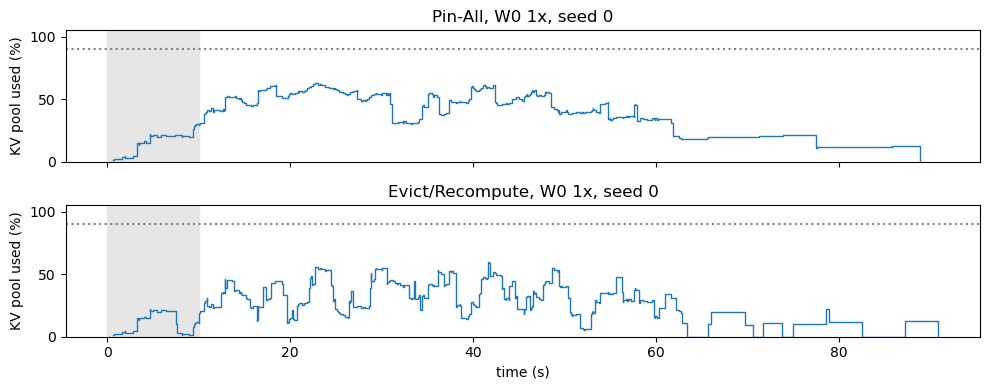

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
occupancy(axes[0], 'pin_all', 'W0', 1, 0, 'Pin-All, W0 1x, seed 0')
occupancy(axes[1], 'evict_recompute', 'W0', 1, 0, 'Evict/Recompute, W0 1x, seed 0')
axes[1].set_xlabel('time (s)')
plt.tight_layout()

**동작 검증**: 15개 run 모두 삭제 횟수가 도구 대기 횟수와 같고, 삭제 사유가 전부 idle이어야 합니다.

In [8]:
check = []
for _, wl, lv in WEEK7_CONDITIONS:
    for seed in WEEK7_SEEDS:
        ev = events('evict_recompute', wl, lv, seed)
        evict = ev[ev.event == 'EVICT']
        check.append(len(evict) == (ev.event == 'TOOL_START').sum() and evict.detail.str.contains('reason=idle').all())
print('evict == tool wait in all runs:', all(check), f'({len(check)} runs)')

evict == tool wait in all runs: True (15 runs)


**얻은 것**: 모든 조건에서 SLO 통과 100%. 최고 점유율 55~64%로 4배에서도 여유가 있습니다.

**대가**: run마다 재계산 토큰 약 12.6만 개. 1초짜리 짧은 대기까지 지우고 매번 다시 계산하기 때문입니다. TTFT 기준은 같은 정책의 W0 대비라 통과하지만, W0 자체가 0.63초로 기준선(0.26초)의 2.4배입니다. normal 요청은 재계산하지 않지만 하나뿐인 prefill 줄에서 재계산 뒤에 서기 때문입니다.

**남은 문제 → 단계 2**: 짧은 대기는 지키고 필요한 만큼만 지울 수 없나.

## 6. 단계 2: Fixed TTL 3초

3초 안에 돌아오는 짧은 대기는 지키고, 넘으면 지웁니다. 3초는 `week7_step_by_step.ipynb` 9절의 1·3·5초 비교에서 고른 값입니다(1초 ≈ 단계 1, 5초 ≈ 기준선).

In [9]:
step2 = judge('fixed_ttl')
display(pd.concat({'Fixed TTL 3s': step2, 'Evict/Recompute (단계 1)': step1}, axis=1).T)

load                                        1x         2x         4x
Fixed TTL 3s           P95 TTFT (s)       0.44       0.44       0.47
                       TTFT / W0          1.00       1.03       1.07
                       거절률 (%)            0.00       0.00       0.00
                       최고 점유율 (%)        66.42      78.77      72.43
                       SLO 통과 (%)       100.00      80.00     100.00
                       삭제                18.20      31.20      36.20
                       재계산 토큰         63749.60  108507.80  126002.80
Evict/Recompute (단계 1) P95 TTFT (s)       0.63       0.49       0.47
                       TTFT / W0          1.00       0.81       0.77
                       거절률 (%)            0.00       0.00       0.00
                       최고 점유율 (%)        63.58      61.37      54.61
                       SLO 통과 (%)       100.00     100.00     100.00
                       삭제                36.20      36.20      36.20
                       재계산 토큰        126002.80  126002.80  126002.80

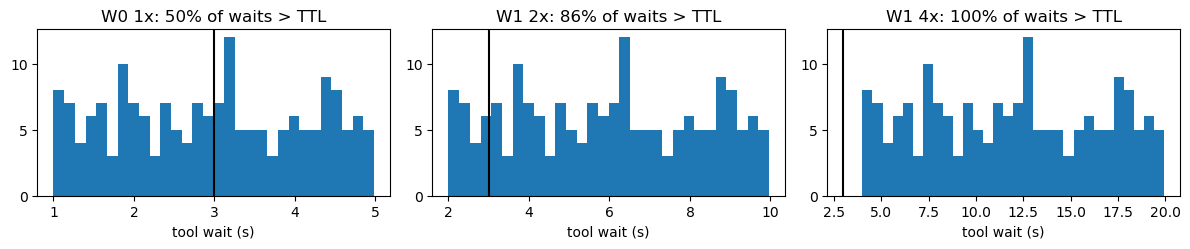

In [10]:
ttl_s = load_policy_params('configs/policies_week7.json', 'fixed_ttl')['ttl_ms'] / 1000
fig, axes = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, (load, wl, lv) in zip(axes, WEEK7_CONDITIONS):
    waits = [t.tool_duration_ms / 1000 for seed in WEEK7_SEEDS for t in generate(workload, wl, lv, seed)
             if t.request_class == 'stress' and t.tool_duration_ms > 0]
    over = sum(w > ttl_s for w in waits) / len(waits) * 100
    ax.hist(waits, bins=30)
    ax.axvline(ttl_s, color='k')
    ax.set(title=f'{wl} {lv}x: {over:.0f}% of waits > TTL', xlabel='tool wait (s)')
plt.tight_layout()

**동작 검증**: 모든 삭제가 TTL 만료로 일어나야 합니다.

In [11]:
share = {}
for load, wl, lv in WEEK7_CONDITIONS:
    evict = expired = idle = 0
    for seed in WEEK7_SEEDS:
        ev = events('fixed_ttl', wl, lv, seed)
        evict += (ev.event == 'EVICT').sum(); expired += (ev.event == 'TTL_EXPIRE').sum(); idle += (ev.event == 'TOOL_START').sum()
    assert evict == expired
    share[load] = evict / idle * 100
print('all evictions come from TTL expiry: True')
display(pd.Series(share, name='evicted waits (%)').round(0))

all evictions come from TTL expiry: True


1x     50.0
2x     86.0
4x    100.0
Name: evicted waits (%), dtype: float64

**얻은 것**: W0에서 대기의 절반만 지워 재계산이 단계 1의 절반(약 6.4만 토큰)이고 TTFT 0.44초입니다.

**한계**: W1 2배에서는 덜 지운 만큼 점유율이 올라 한 seed가 90%를 넘고(통과 80%), W1 4배는 대기가 전부 3초를 넘어 숫자까지 단계 1과 같아집니다. 고정값 하나는 분포가 바뀌면 따라가지 못하고, 지우는 한 재계산은 남습니다.

**남은 문제 → 단계 3**: 지우지 말고 옮기면 어떨까.

## 7. 단계 3: LRU Offload

평소에는 유지하다가 블록이 모자랄 때만, 가장 오래 기다린 세션부터 CPU 메모리로 내립니다. 복귀하면 PCIe로 다시 올립니다(재계산 없음).

In [12]:
step3 = judge('lru_offload')
display(pd.concat({'LRU Offload': step3, 'Pin-All (기준선)': base}, axis=1).T)

load                            1x     2x     4x
LRU Offload   P95 TTFT (s)    0.26   0.26   0.26
              TTFT / W0       1.00   1.01   1.00
              거절률 (%)         0.00   0.00   0.00
              최고 점유율 (%)     66.29  85.25  98.02
              SLO 통과 (%)    100.00  60.00   0.00
              삭제              0.00   0.00   0.00
              재계산 토큰          0.00   0.00   0.00
Pin-All (기준선) P95 TTFT (s)    0.26   0.26  14.23
              TTFT / W0       1.00   1.01  61.33
              거절률 (%)         0.00   0.00   1.99
              최고 점유율 (%)     66.29  85.25  98.41
              SLO 통과 (%)    100.00  60.00   0.00
              삭제              0.00   0.00   0.00
              재계산 토큰          0.00   0.00   0.00

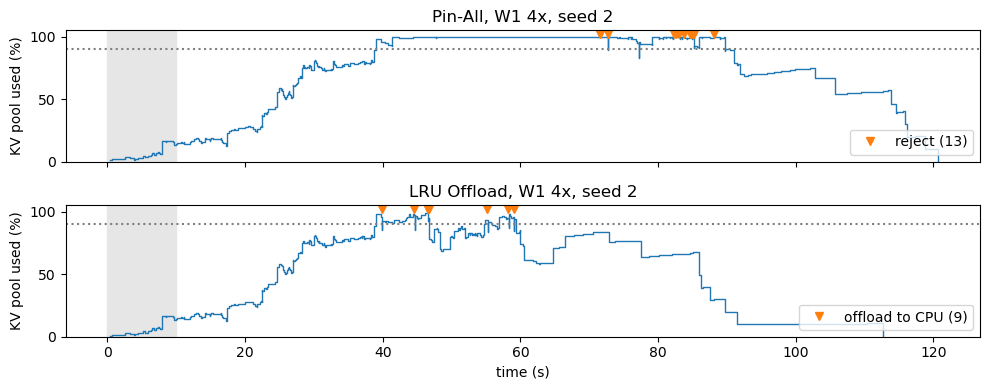

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
occupancy(axes[0], 'pin_all', 'W1', 4, 2, 'Pin-All, W1 4x, seed 2')
r = events('pin_all', 'W1', 4, 2).query("event == 'REJECT'").time_ms / 1000
axes[0].plot(r, [102] * len(r), 'v', label=f'reject ({len(r)})'); axes[0].legend(loc='lower right')
occupancy(axes[1], 'lru_offload', 'W1', 4, 2, 'LRU Offload, W1 4x, seed 2')
o = events('lru_offload', 'W1', 4, 2).query("event == 'OFFLOAD_START'").time_ms / 1000
axes[1].plot(o, [102] * len(o), 'v', label=f'offload to CPU ({len(o)})'); axes[1].legend(loc='lower right')
axes[1].set_xlabel('time (s)')
plt.tight_layout()

**동작 검증**: 오프로드는 블록 부족(pressure) 시점에만 일어나야 하고, 내린 횟수와 다시 올린 횟수가 같아야 합니다.

In [14]:
ok = True
for _, wl, lv in WEEK7_CONDITIONS:
    for seed in WEEK7_SEEDS:
        ev = events('lru_offload', wl, lv, seed)
        off = ev[ev.event == 'OFFLOAD_START']
        ok &= bool(off.detail.str.contains('reason=pressure').all()) and len(off) == (ev.event == 'RELOAD_START').sum()
print('offload only under pressure and offload == reload:', ok)
cost = raw[raw.policy == 'lru_offload'].groupby('stress_level')[['offload_count', 'pcie_busy_pct']].mean()
cost.index = LOADS
display(cost)

offload only under pressure and offload == reload: True


,offload_count,pcie_busy_pct
1x,0.0,0.00
2x,0.0,0.00
4x,4.6,0.22


**얻은 것**: 재계산 0, 4배에서도 TTFT가 W0의 1.0배이고 거절 0입니다. 4배에서도 run당 4~5번만 옮겼습니다.

**한계**: 블록이 다 찬 뒤에야 옮기는 설계라 최고 점유율이 기준선과 같이 85~98%까지 오르고, 점유율 기준에서 2배 60% · 4배 0%로 떨어집니다. 또 PCIe 12 GB/s · CPU 64 GiB가 자리표시자라 전송 비용이 거의 0으로 잡혔으므로 실측 후 다시 확인해야 합니다.

## 8. 종합: 같은 판정 기준으로 네 정책 비교

In [15]:
pass_table = comparison.pivot(index='policy', columns='load', values='all_slo_pass_rate_pct').loc[list(POLICIES), LOADS]
pass_table.index = [LABEL[p] for p in POLICIES]
pass_table['재계산 토큰 (W1 4x)'] = comparison.set_index(['policy', 'load']).loc[[(p, '4x') for p in POLICIES], 'recomputed_tokens_mean'].values
display(pass_table.rename_axis('SLO 통과 (%)'))

load,1x,2x,4x,재계산 토큰 (W1 4x)
SLO 통과 (%),,,,
Pin-All,100.0,60.0,0.0,0.0
Evict/Recompute,100.0,100.0,100.0,126002.8
Fixed TTL 3s,100.0,80.0,100.0,126002.8
LRU Offload,100.0,60.0,0.0,0.0


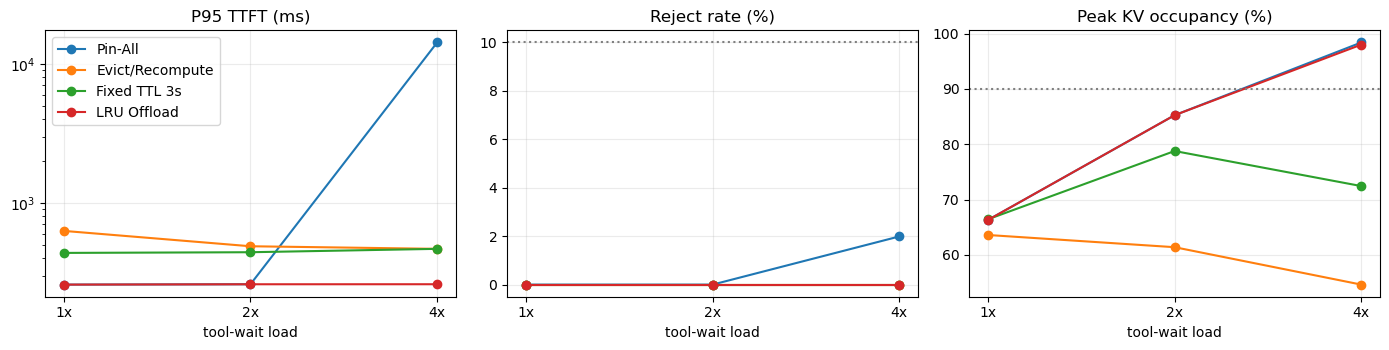

In [16]:
metrics = [('normal_p95_ttft_ms_mean', 'P95 TTFT (ms)', 'log', None),
           ('normal_reject_rate_pct_mean', 'Reject rate (%)', 'linear', 10),
           ('peak_kv_occupancy_pct_mean', 'Peak KV occupancy (%)', 'linear', 90)]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (metric, title, scale, limit) in zip(axes, metrics):
    for p in POLICIES:
        part = comparison[comparison.policy == p].set_index('load').loc[LOADS]
        ax.plot(LOADS, part[metric], marker='o', label=LABEL[p])
    if limit:
        ax.axhline(limit, color='gray', ls=':')
    ax.set(title=title, xlabel='tool-wait load', yscale=scale)
    ax.grid(alpha=.25)
axes[0].legend()
plt.tight_layout()

## 9. 결론과 해석 범위

| 단계 | 얻은 것 | 대가 · 남은 문제 |
|---|---|---|
| 기준선 Pin-All | 1배에서 가장 빠름 (0.26s) | 2배부터 점유율 초과, 4배는 TTFT 61배 → SLO 0% |
| 단계 1 Evict/Recompute | 전 조건 SLO 통과 100% | run당 재계산 약 12.6만 토큰, W0 TTFT 기준선의 2.4배 |
| 단계 2 Fixed TTL 3s | W0 재계산 절반 | 2배에서 점유율 초과 1 seed, 4배는 단계 1과 같아짐 |
| 단계 3 LRU Offload | 재계산 0 · TTFT 유지 · 거절 0 | 다 찬 뒤에 옮겨 점유율 기준 탈락 (2배 60% · 4배 0%), 전송 비용 실측 필요 |

- 세 기준을 모든 조건에서 지킨 정책은 단계 1뿐이고, 대가는 재계산입니다. 재계산을 줄인 단계 2·3은 점유율 기준에서 떨어집니다.
- 다음 과제: 점유율 90%를 지키면서 재계산을 줄이는 정책(예: 동적 TTL, 90% 전에 미리 옮기는 Offload)을 같은 기준으로 붙입니다.
- 시뮬레이터 가정: prefill 단일 FIFO(실제 vLLM은 배치), 세션 간 decode 경합 없음, 속도 자리표시자. 절대값이 아니라 같은 가정 아래의 정책 간 변화로만 해석합니다.